# Supervised multi-subject brain-to-text

**Question.** Does pooling several people's intracortical recordings into *one* decoder beat training a separate decoder per person?

This notebook trains a single **neural → characters** (CTC) model across three BrainGate2 participants and compares it, subject by subject, against isolated per-subject baselines. It is the first of two experiments; [`02_pretrain_finetune.ipynb`](02_pretrain_finetune.ipynb) adds self-supervised pretraining on top of exactly this pipeline.

## The study collection (neural → text)

| Study | Subject | Cortex | Spikes | Spike-band power | Task |
|---|---|---|---|---|---|
| `card_2024` | T15 | speech precentral | 256 ch | 256 ch | attempted speech |
| `willett_2023` | T12 | speech precentral | 256 ch | 256 ch | attempted speech |
| `fan_h2` | T5 | hand-knob motor | 192 ch | — (none) | attempted handwriting |

Three subjects, three implants, two paradigms, **different channel counts**, and one of them has no spike-band power. The only thing they share is the decode target: a line of English text. That mismatch is the whole challenge — and the reason the model is built the way it is.

## The architecture (one model, many sessions)

```
 spikes (B, C_spike, T) ─┐
                         ├─[ per-SESSION read-in ]─► (B,T,D) ─┐
 sbp    (B, C_sbp,  T) ─┘   (+ optional SBP head)             ├─ + region emb + subject emb
                                                              ▼
                                        shared conv + BiGRU backbone
                                                              │ (B,T',2H)
                                                     CTC head ▼ ► characters
```

- **Per-session read-in adapters** absorb the channel-count mismatch: each recording session gets its own linear map into a shared width `D`. A new session/subject is just a new adapter.
- **Region + subject embeddings** tell the shared backbone where each clip came from.
- **The backbone and CTC head are shared** across everyone — that shared part is what pooling trains.

All of this lives in [`neuralshed.models`](.); the notebook drives it.

In [1]:
import os, logging, warnings; warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"     # neuralset's prepare() progress bars
logging.disable(logging.INFO)        # its extractors log per-event at INFO
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightning as L; L.seed_everything(0, workers=True)

from neuralshed.models import (
    speech_text_collection, collection_identities,
    BrainToTextCTC, make_loader, train_ctc, evaluate_by_subject,
)
from neuralshed.models.bit import BitDataBundle

# --- experiment configuration -------------------------------------------------
MEMBERS  = ("card_2024", "willet_2023", "fan_h2")
# What this collection is *for*: which event classes it reads and which it decodes. Inputs are
# wanted-if-present, so fan_h2 (no band power) joins with one input layout instead of two.
INPUTS   = ("SpikeCounts", "BandPower")
TARGETS  = ("Sentence",)
QUERY    = "session_index < 2"   # keep the notebook light; two sessions per member
EPOCHS   = 24          # cosine-annealed; the head's blank-bias init avoids the all-blank collapse
BATCH    = 32
LR       = 3e-3
MAX_TRIALS_PER_PARTICIPANT = 350   # balance each person's share, round-robin across their adapters
MODEL_KW = dict(d_model=256, hidden=128, gru_layers=1, strides=(2, 2))

## Step 1 — Assemble the pooled dataset

`BitDataBundle.from_collection` is the one path from Studies to training tensors in this repo. It runs the collection's step chain, preflights it, resolves a manifest, windows every valid target into `(neural, character-ids)`, and does the bookkeeping that makes pooling safe:

- a **per-adapter key** for every recording layout, so read-in adapters and normalization never collide across studies,
- **per-adapter, per-channel z-scoring fitted on training trials only** (card ships z-scored features, willett ships raw µV², fan ships raw counts), with card flagged `already_normalized` so it is left alone,
- a **frozen character vocabulary** (id 0 is the CTC blank) that does not depend on which collection was assembled.

`SpikeCounts` (threshold crossings) is the primary input and `BandPower` (spike-band power) a separate optional stream, so they hit separate read-in heads and a missing modality is an absent tensor rather than a block of zeros.

The BIT decoder in [`04_bit_pipeline.ipynb`](04_bit_pipeline.ipynb) starts from this same object, which is what makes a CER comparison between the two models a comparison of *models*.

In [2]:
# One pipeline feeds every model in this repo. The collection is a runnable step chain
# (CombineStudies -> StandardizeText -> ValidateTarget -> AssignHashSplit); BitDataBundle runs
# it, preflights it, resolves a manifest, segments each trial, and fits normalization on the
# training split only. The BIT notebook (04) starts from exactly this object.
bundle = BitDataBundle.from_collection(
    speech_text_collection(MEMBERS, query=QUERY),
    inputs=INPUTS,
    targets=TARGETS,
    **collection_identities(MEMBERS),
).subset(max_trials_per_participant=MAX_TRIALS_PER_PARTICIPANT)

trials, vocab, manifest = bundle.trials, bundle.vocab, bundle.manifest
print(bundle, "\n dropped:", bundle.dropped)

preflight OK
  events: 2847
  targets: 1429
  targets per member: {'willet_2023': 680, 'card_2024': 671, 'fan_h2': 78}
  vocabulary: v1 (29 classes)
  split: {'train': 1131, 'val': 161, 'test': 137}
  adapters: 6
  participants: ['braingate2/T12', 'braingate2/T15', 'braingate2/T5']
  regions: ['handknob_motor', 'speech_precentral']
  modalities: ['spike_counts', 'band_power']
  native rates (Hz): [50.0]
  warning 2 of 6 adapters have no band_power; those read-ins run on threshold crossings alone


2026-07-28 20:16:20 - WARNING - neuralset.segments:682 - 6 segments out of 30 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


2026-07-28 20:16:20 - WARNING - neuralset.segments:682 - 6 segments out of 30 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


2026-07-28 20:16:20 - WARNING - neuralset.segments:682 - 9 segments out of 48 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


2026-07-28 20:16:20 - WARNING - neuralset.segments:682 - 9 segments out of 48 did not contain valid events for event type <class 'neuralshed.events.SpikeCounts'>


bundle: 1414 trials, 6 adapters, 3 participants, dropped={'no_target': 0, 'too_short': 0, 'empty_window': 0, 'no_signal': 15}
BitDataBundle(763 trials {'test': 66, 'train': 602, 'val': 95}, 6 adapters, n_classes=29) 
 dropped: {'no_target': 0, 'too_short': 0, 'empty_window': 0, 'no_signal': 15}


Each **adapter** becomes a row below — one per recording session by default. Note the heterogeneity the model must absorb: 256 vs 192 spike channels, and `sbp_ch = 0` for the fan_h2 (T5) sessions, which simply skip the SBP head.

In [3]:
# One row per stream, not per recording: channel count and rate belong to the stream, and a
# member with no band power simply has no such row.
manifest.to_frame()[
    ["layout_key", "event_type", "kind", "role", "participant", "channels", "native_rate"]
]

,adapter,participant,region,spike_ch,sbp_ch,sessions
0,card_2024/t15.2023.08.11,braingate2/T15,speech_precentral,256,256,1
1,card_2024/t15.2023.08.13,braingate2/T15,speech_precentral,256,256,1
2,fan_h2/sub-T5-held-in-calib_ses-20220518,braingate2/T5,handknob_motor,192,0,1
3,fan_h2/sub-T5-held-in-calib_ses-20220523,braingate2/T5,handknob_motor,192,0,1
4,willet_2023/t12.2022.04.28,braingate2/T12,speech_precentral,256,256,1
5,willet_2023/t12.2022.05.05,braingate2/T12,speech_precentral,256,256,1


## Step 2 — Peek at a training batch

A batch is deliberately drawn from a **single session** (a `SessionBatchSampler`), so it has one fixed channel count and one adapter applies per forward pass. The CTC target is the flat concatenation of every clip's character ids, with a separate length vector.

In [4]:
train_loader = bundle.train_loader(batch_size=BATCH)
val_loader   = bundle.val_loader(batch_size=BATCH)

b = next(iter(train_loader))
print("recording   :", b["group_key"])
for stream, tensor in b["arrays"].items():
    print(f"{stream:12}:", tuple(tensor.shape), "->", b["layouts"][stream])
print("targets     :", tuple(b["targets"].shape), " target_lengths sum =", int(b["target_lengths"].sum()))
print("participant :", manifest.participants[b["participant_idx"][0]])
print("example     :", repr(b["texts"][0]))

spike_counts: (9, 256, 790)   (B, C_spike, T)
band_power  : (9, 256, 790)
targets     : (458,)  target_lengths sum = 458
participant : braingate2/T12
example     : 'the jaw operates by using antagonistic muscles'


## Step 3 — The model

`BrainToTextCTC.from_manifest` builds one read-in adapter per manifest entry, adds region and participant embeddings, and shares the backbone + CTC head. It reads the same manifest BIT's read-in reads. Below, notice how few parameters are *adapter-specific* versus *shared* — the shared part is the cross-participant representation pooling is meant to improve.

In [5]:
model = BrainToTextCTC.from_manifest(manifest, vocab.n_classes, bundle.state, frequency=50.0, **MODEL_KW)
n_readin  = sum(p.numel() for p in model.readin.parameters())
n_backbone = sum(p.numel() for p in model.backbone.parameters()) + sum(p.numel() for p in model.ctc_head.parameters())
print(f"layout-specific (read-in)  : {n_readin:,} params  ({len(manifest.array_layouts)} input layouts)")
print(f"shared (backbone + head)   : {n_backbone:,} params")
print(f"total                      : {sum(p.numel() for p in model.parameters()):,}")

adapter-specific (read-in) : 626,944 params  (6 adapters)
shared (backbone + head)   : 959,773 params
total                      : 1,948,573


## Step 4 — Isolated baselines (one model per participant)

For each participant we carve their adapters out of the pooled bundle with `bundle.subset(participants=[...])`, which re-derives the manifest and repacks the indices, so the isolated model's embedding tables are sized for one person rather than for people it never sees. This is the "no pooling" control.

In [6]:
# `bundle.subset` filters the manifest, so an isolated model gets embedding tables sized for
# one participant rather than for people it never sees. Layout keys are preserved rather than
# recomputed, so the isolated and pooled runs name the same layouts and stay comparable.
isolated = {}
for person in manifest.participants:
    solo = bundle.subset(participants=[person])
    m = BrainToTextCTC.from_manifest(solo.manifest, vocab.n_classes, solo.state, frequency=50.0, **MODEL_KW)
    tr = solo.train_loader(batch_size=BATCH)
    va = solo.val_loader(batch_size=BATCH)
    train_ctc(m, vocab, tr, va, max_epochs=EPOCHS, lr=LR, accelerator="cpu")
    isolated[person] = evaluate_by_subject(m, va, vocab, solo.manifest)[person]
    print(f"  isolated {person}: CER {isolated[person]:.1f}%")

  isolated braingate2/T12: CER 73.3%


  isolated braingate2/T15: CER 87.3%


  isolated braingate2/T5: CER 94.7%


## Step 5 — The pooled model (one model, all three subjects)

Same architecture, same total epochs — but now a single shared backbone sees every subject. Consecutive batches come from different people, so each gradient step updates the shared representation with cross-subject signal.

In [7]:
pooled_model = BrainToTextCTC.from_manifest(manifest, vocab.n_classes, bundle.state, frequency=50.0, **MODEL_KW)
train_ctc(pooled_model, vocab, train_loader, val_loader, max_epochs=EPOCHS, lr=LR, accelerator="cpu")
pooled = evaluate_by_subject(pooled_model, val_loader, vocab, manifest)
print("pooled CER by participant:", {k: round(v, 1) for k, v in pooled.items()})

pooled CER by participant: {'braingate2/T15': 73.8, 'braingate2/T5': 84.0, 'braingate2/T12': 74.1, 'overall': 74.4}


## Step 6 — Isolated vs pooled

The comparison that answers the question. Lower CER is better; the interesting cell is the weakest, most data-starved subject — the one cross-subject pooling is most likely to rescue.

,isolated,pooled,delta
participant,,,
braingate2/T12,73.300000,74.100000,0.8
braingate2/T15,87.300000,73.800000,-13.5
braingate2/T5,94.700000,84.000000,-10.7
overall,85.105015,74.420553,NaN


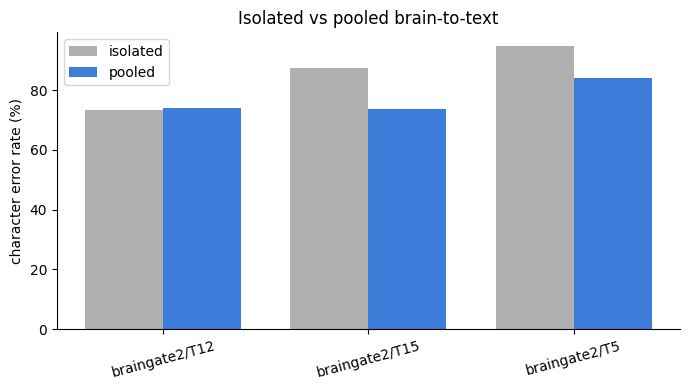

In [8]:
people = manifest.participants
rows = [dict(participant=s, isolated=isolated[s], pooled=pooled[s], delta=pooled[s] - isolated[s])
        for s in people]
tbl = pd.DataFrame(rows).set_index("participant").round(1)
tbl.loc["overall"] = [np.mean([r["isolated"] for r in rows]), pooled["overall"], np.nan]
display(tbl)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(people)); w = 0.38
ax.bar(x - w/2, [isolated[s] for s in people], w, label="isolated", color="#b0b0b0")
ax.bar(x + w/2, [pooled[s]   for s in people], w, label="pooled",   color="#3b7dd8")
ax.set_xticks(x); ax.set_xticklabels(people, rotation=15)
ax.set_ylabel("character error rate (%)"); ax.set_title("Isolated vs pooled brain-to-text")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Takeaways

- **The plumbing works end-to-end**: three subjects with different implants, channel counts, and tasks flow through one model via per-session read-in adapters and a shared backbone.
- **Read the per-subject deltas, not just the average.** Pooling tends to help the data-starved subject most (it borrows structure the others provide) and least the subject that already had enough of its own data — the classic pooling / transfer trade-off.
- **Trust the direction, not the exact numbers.** Char-level CTC on this little data is noisy: the same model re-run with a different seed moves by roughly ±10% CER. The *direction* (pooled below isolated) reproduces across seeds; a single run's magnitude will wobble. Averaging a few seeds per bar is the honest way to pin the size of the effect.
- **This is a small, CPU-sized demo.** Few sessions and a couple dozen epochs, so absolute CER is high; the point is the *method* and the *isolated-vs-pooled direction*. Scaling data, sessions, and epochs is the obvious next lever.
- **What pooling could not use here:** the label-free structure in every recording. That is exactly what the second experiment adds — self-supervised pretraining of the shared backbone before the CTC head ever sees a character. Continue in [`02_pretrain_finetune.ipynb`](02_pretrain_finetune.ipynb).